# Which layer-1 head constructs character count?

This notebook probes each layer-1 head's raw output and residual-space contribution, then zero-ablates each head and evaluates a clean post-layer-1 count probe.

In [1]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd, torch
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, Path.cwd().parent.parent.parent] if (p / "results/line_breaks_results").exists())
sys.path.insert(0, str(ROOT / "src"))
import project_main.checkpoints as checkpoints
import project_main.data as data
import project_main.model as model_lib
import project_main.tokens as tokens_lib

TRAIN_SEED, EVAL_SEED = 9011, 9012
N_TRAIN = N_EVAL = 256
BATCH_SIZE = 32
Z_SITE = "blocks.1.attn.hook_z"
PRE_SITE, MID_SITE, POST_SITE = "blocks.1.hook_resid_pre", "blocks.1.hook_resid_mid", "blocks.1.hook_resid_post"
cfg = json.loads((ROOT / "results/line_breaks_results/config.json").read_text())
device = "cuda" if torch.cuda.is_available() else "cpu"
vocab = tokens_lib.build_vocab(cfg["task"])
model = model_lib.build_model(cfg=cfg, device=device)
checkpoint = checkpoints.load_checkpoint(path=ROOT / "results/line_breaks_results/checkpoints/final.pt", model=model, map_location=device)
model.eval(); n_heads = cfg["model"]["n_heads"]

def collect(n, seed):
    toks, zs, pres, mids, posts, labs = [], [], [], [], [], []
    names = [Z_SITE, PRE_SITE, MID_SITE, POST_SITE]
    for start in range(0, n, BATCH_SIZE):
        size = min(BATCH_SIZE, n - start); batch = data.make_batch(size, vocab, cfg["task"], device, seed + start)
        with torch.no_grad(): _, cache = model.run_with_cache(batch.tokens, prepend_bos=False, names_filter=names)
        t = batch.tokens.detach().cpu().numpy(); toks.append(t); zs.append(cache[Z_SITE].detach().cpu().numpy()); pres.append(cache[PRE_SITE].detach().cpu().numpy()); mids.append(cache[MID_SITE].detach().cpu().numpy()); posts.append(cache[POST_SITE].detach().cpu().numpy())
        y = np.zeros(t.shape, dtype=np.int64)
        for b, row in enumerate(t):
            count = 0
            for p, token_id in enumerate(row):
                name = vocab.decode_token(int(token_id))
                if name in {"BOS", "_NEWLINE_"}: count = 0
                else: count += data.extract_character_count(name); y[b, p] = count
        labs.append(y)
    return np.concatenate(toks), np.concatenate(zs), np.concatenate(pres), np.concatenate(mids), np.concatenate(posts), np.concatenate(labs)

train_tokens, train_z, train_pre, train_mid, train_post, train_y = collect(N_TRAIN, TRAIN_SEED)
eval_tokens, eval_z, eval_pre, eval_mid, eval_post, eval_y = collect(N_EVAL, EVAL_SEED)
train_mask, eval_mask = train_y.ravel() > 0, eval_y.ravel() > 0
print("checkpoint", checkpoint["step"], "device", device, "heads", n_heads)
print("train/eval", len(train_tokens), len(eval_tokens), "positive eval positions", int(eval_mask.sum()))


Building vocab...
('BOS', '_NEWLINE_')


checkpoint 10000 device cpu heads 4
train/eval 256 256 positive eval positions 36066


## Head-wise count probes

In [2]:
def fit_probe(Xtr, ytr, Xev, yev):
    p = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(Xtr, ytr); pred = p.predict(Xev)
    return r2_score(yev, pred), mean_absolute_error(yev, pred)
rows = []
for head in range(n_heads):
    ztr = train_z.reshape(-1, n_heads, train_z.shape[-1])[:, head][train_mask]; zev = eval_z.reshape(-1, n_heads, eval_z.shape[-1])[:, head][eval_mask]
    W_O = model.W_O[1, head].detach().cpu().numpy(); otr, oev = ztr @ W_O, zev @ W_O
    for representation, Xtr, Xev in [("raw_z", ztr, zev), ("residual_contribution", otr, oev)]:
        r2, mae = fit_probe(Xtr, train_y.ravel()[train_mask], Xev, eval_y.ravel()[eval_mask]); rows.append({"head": head, "representation": representation, "R2": r2, "MAE": mae})
head_probe_results = pd.DataFrame(rows)
print("Linear count probes on individual layer-1 heads"); display(head_probe_results.round(4))


Linear count probes on individual layer-1 heads


,head,representation,R2,MAE
0,0,raw_z,0.0969,18.9593
1,0,residual_contribution,0.0965,18.9556
2,1,raw_z,0.9752,2.9050
3,1,residual_contribution,0.9741,2.9576
4,2,raw_z,0.1398,18.3749
5,2,residual_contribution,0.1405,18.3515
6,3,raw_z,0.1108,18.7098
7,3,residual_contribution,0.1115,18.6876


## Causal head ablations

In [3]:
clean_probe = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(train_post.reshape(-1, 128)[train_mask], train_y.ravel()[train_mask])
clean_pred = clean_probe.predict(eval_post.reshape(-1, 128)[eval_mask])
ablation_rows = [{"head": "clean", "R2": r2_score(eval_y.ravel()[eval_mask], clean_pred), "MAE": mean_absolute_error(eval_y.ravel()[eval_mask], clean_pred)}]
for head in range(n_heads):
    ablated_posts = []
    for start in range(0, len(eval_tokens), BATCH_SIZE):
        tokens = torch.as_tensor(eval_tokens[start:start + BATCH_SIZE], device=device); captured = {}
        def zero_selected(z, hook, selected=head):
            z = z.clone(); z[:, :, selected, :] = 0; return z
        def capture_post(x, hook): captured["post"] = x.detach().cpu(); return x
        with torch.no_grad(): model.run_with_hooks(tokens, prepend_bos=False, fwd_hooks=[(Z_SITE, zero_selected), (POST_SITE, capture_post)])
        ablated_posts.append(captured["post"].numpy())
    ablated = np.concatenate(ablated_posts); pred = clean_probe.predict(ablated.reshape(-1, 128)[eval_mask])
    ablation_rows.append({"head": head, "R2": r2_score(eval_y.ravel()[eval_mask], pred), "MAE": mean_absolute_error(eval_y.ravel()[eval_mask], pred)})
ablation_results = pd.DataFrame(ablation_rows)
print("Clean post-layer-1 count probe under layer-1 head zero ablation"); display(ablation_results.round(4))


Clean post-layer-1 count probe under layer-1 head zero ablation


,head,R2,MAE
0,clean,0.9969,0.9902
1,0,0.9896,1.9283
2,1,-1.2870,29.9623
3,2,0.9668,3.7937
4,3,0.9282,5.2966


## Figures

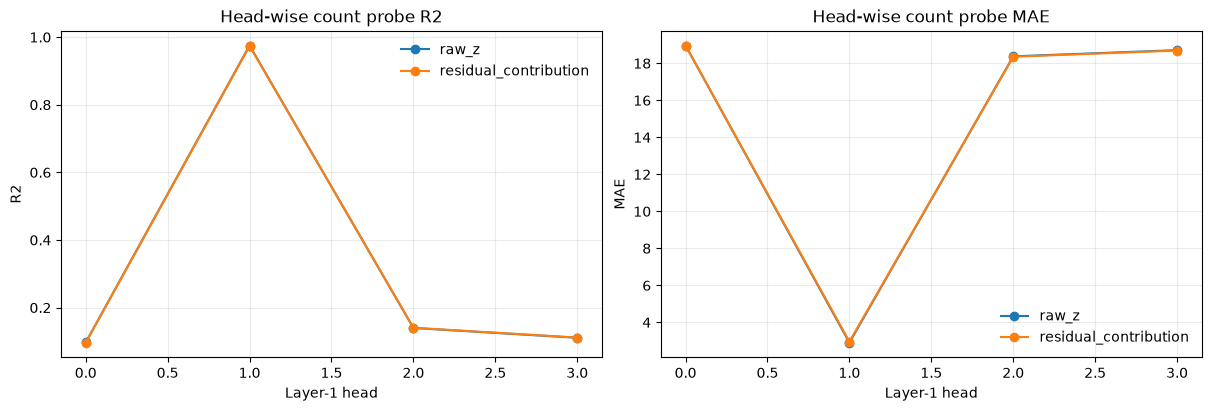

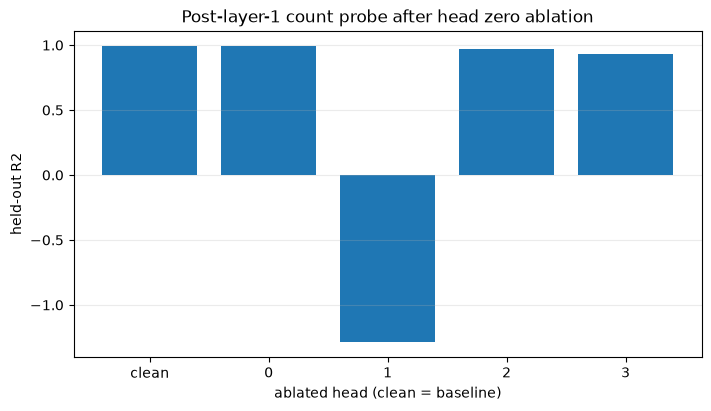

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for rep, group in head_probe_results.groupby("representation"):
    axes[0].plot(group["head"], group.R2, marker="o", label=rep); axes[1].plot(group["head"], group.MAE, marker="o", label=rep)
axes[0].set_title("Head-wise count probe R2"); axes[0].set_ylabel("R2"); axes[1].set_title("Head-wise count probe MAE"); axes[1].set_ylabel("MAE")
for ax in axes: ax.set_xlabel("Layer-1 head"); ax.grid(alpha=.25); ax.legend(frameon=False)
plt.show()
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True); ax.bar(ablation_results["head"].astype(str), ablation_results.R2); ax.set_title("Post-layer-1 count probe after head zero ablation"); ax.set_xlabel("ablated head (clean = baseline)"); ax.set_ylabel("held-out R2"); ax.grid(axis="y", alpha=.25); plt.show()
